In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [5]:
df=pd.read_csv("loanapproval.csv")

In [6]:
df.head()

,applicant_id,age,gender,marital_status,annual_income,loan_amount,credit_score,num_dependents,existing_loans_count,employment_status,loan_approved
0,1,59,Male,Divorced,100073,7169,793,1,1,Unemployed,1
1,2,49,Male,Married,112197,23556,789,0,2,Employed,1
2,3,35,Male,Divorced,84429,27052,372,1,4,Unemployed,0
3,4,63,Female,Single,124195,11313,808,3,4,Self-employed,1
4,5,28,Female,Married,81627,13315,689,0,1,Unemployed,1


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   applicant_id          1000 non-null   int64 
 1   age                   1000 non-null   int64 
 2   gender                1000 non-null   object
 3   marital_status        1000 non-null   object
 4   annual_income         1000 non-null   int64 
 5   loan_amount           1000 non-null   int64 
 6   credit_score          1000 non-null   int64 
 7   num_dependents        1000 non-null   int64 
 8   existing_loans_count  1000 non-null   int64 
 9   employment_status     1000 non-null   object
 10  loan_approved         1000 non-null   int64 
dtypes: int64(8), object(3)
memory usage: 86.1+ KB


In [8]:
df.isnull().sum()

applicant_id            0
age                     0
gender                  0
marital_status          0
annual_income           0
loan_amount             0
credit_score            0
num_dependents          0
existing_loans_count    0
employment_status       0
loan_approved           0
dtype: int64

In [9]:
df.describe()

,applicant_id,age,annual_income,loan_amount,credit_score,num_dependents,existing_loans_count,loan_approved
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000
mean,500.500000,42.515000,81972.972000,27244.866000,576.125000,1.97700,2.042000,0.729000
std,288.819436,12.611059,37547.255418,12822.752877,155.921483,1.41862,1.413589,0.444699
min,1.000000,21.000000,20155.000000,5082.000000,300.000000,0.00000,0.000000,0.000000
25%,250.750000,32.000000,48913.250000,16587.500000,443.750000,1.00000,1.000000,0.000000
50%,500.500000,43.000000,82050.000000,27041.500000,573.500000,2.00000,2.000000,1.000000
75%,750.250000,53.000000,113556.000000,37939.250000,713.250000,3.00000,3.000000,1.000000
max,1000.000000,64.000000,149951.000000,49864.000000,849.000000,4.00000,4.000000,1.000000


In [10]:
df.shape

(1000, 11)

#Handle Missing Values

In [11]:
categorical_cols=df.select_dtypes(include=["object"]).columns
numerical_cols=df.select_dtypes(include=["int64"]).columns

In [12]:
categorical_cols

Index(['gender', 'marital_status', 'employment_status'], dtype='object')

In [13]:
numerical_cols

Index(['applicant_id', 'age', 'annual_income', 'loan_amount', 'credit_score',
       'num_dependents', 'existing_loans_count', 'loan_approved'],
      dtype='object')

In [14]:
from sklearn.impute import SimpleImputer

num_imp=SimpleImputer(strategy="mean")
df[numerical_cols]=num_imp.fit_transform(df[numerical_cols])

In [15]:
df

,applicant_id,age,gender,marital_status,annual_income,loan_amount,credit_score,num_dependents,existing_loans_count,employment_status,loan_approved
0,1.0,59.0,Male,Divorced,100073.0,7169.0,793.0,1.0,1.0,Unemployed,1.0
1,2.0,49.0,Male,Married,112197.0,23556.0,789.0,0.0,2.0,Employed,1.0
2,3.0,35.0,Male,Divorced,84429.0,27052.0,372.0,1.0,4.0,Unemployed,0.0
3,4.0,63.0,Female,Single,124195.0,11313.0,808.0,3.0,4.0,Self-employed,1.0
4,5.0,28.0,Female,Married,81627.0,13315.0,689.0,0.0,1.0,Unemployed,1.0
...,...,...,...,...,...,...,...,...,...,...,...
995,996.0,53.0,Female,Married,135598.0,6014.0,767.0,3.0,2.0,Employed,1.0
996,997.0,22.0,Male,Single,139028.0,15103.0,662.0,0.0,0.0,Self-employed,1.0
997,998.0,34.0,Female,Married,147517.0,21986.0,582.0,0.0,2.0,Employed,1.0
998,999.0,60.0,Female,Divorced,73161.0,49781.0,635.0,4.0,0.0,Unemployed,1.0


In [16]:
cat_imp=SimpleImputer(strategy="most_frequent")
df[categorical_cols]=cat_imp.fit_transform(df[categorical_cols])

# EDA

Text(0.5, 1.0, 'Is Loan approved or not?')

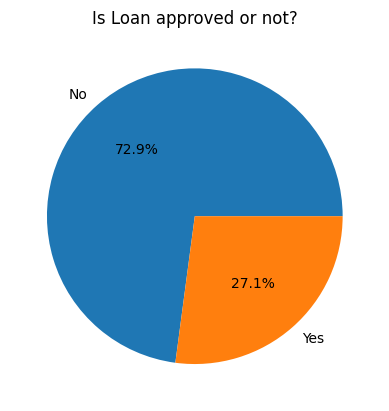

In [17]:
# how balance our classes are?
classes_count=df["loan_approved"].value_counts()
plt.pie(classes_count,labels=["No","Yes"],autopct="%1.1f%%")
plt.title("Is Loan approved or not?")

[Text(0, 0, '524'), Text(0, 0, '476')]

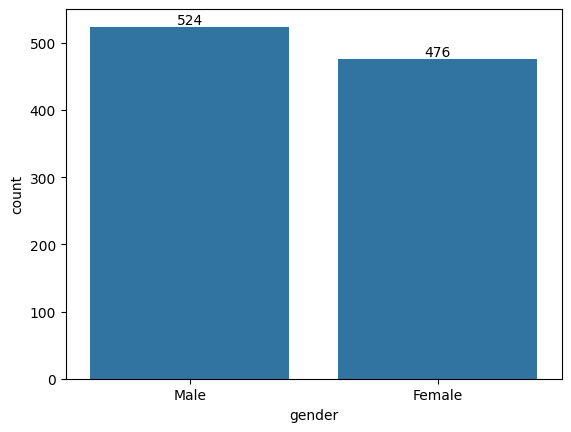

In [18]:
# analyses Categories
gender_count=df["gender"].value_counts()
ax=sns.barplot(gender_count)
ax.bar_label(ax.containers[0])

[Text(0, 0, '355'), Text(0, 0, '342'), Text(0, 0, '303')]

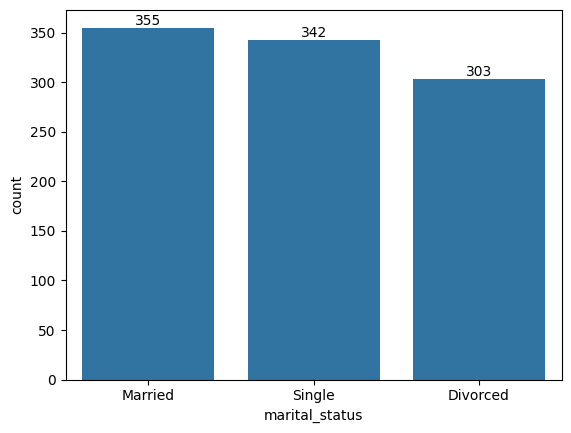

In [19]:
martial_count=df["marital_status"].value_counts()
ax=sns.barplot(martial_count)
ax.bar_label(ax.containers[0])

[Text(0, 0, '350'), Text(0, 0, '330'), Text(0, 0, '320')]

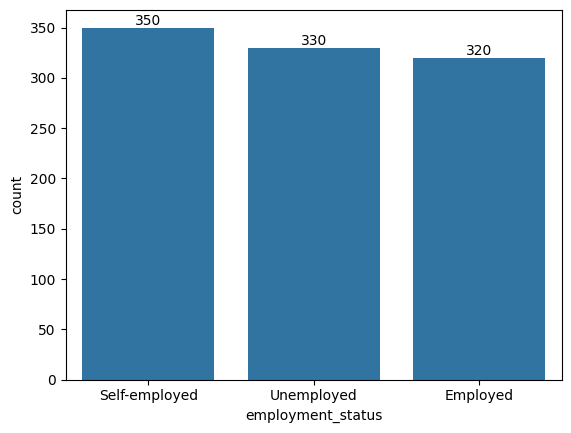

In [20]:
employ_count=df["employment_status"].value_counts()
ax=sns.barplot(employ_count)
ax.bar_label(ax.containers[0])

<Axes: xlabel='annual_income', ylabel='Count'>

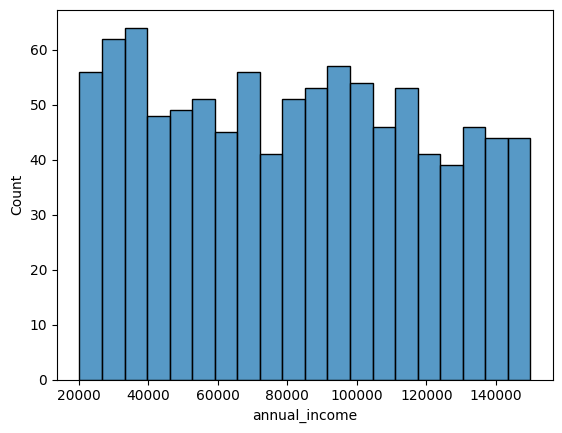

In [21]:
# Analyses Income
sns.histplot(
    data=df,
    x="annual_income",
    bins=20
)

<Axes: xlabel='loan_amount', ylabel='Count'>

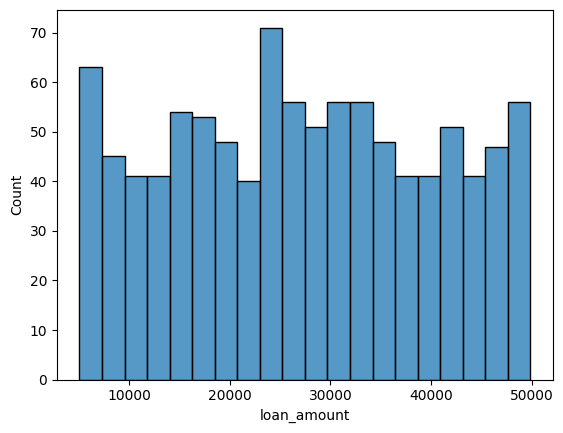

In [22]:
sns.histplot(
    data=df,
    x="loan_amount",
    bins=20
)

<Axes: xlabel='loan_approved', ylabel='annual_income'>

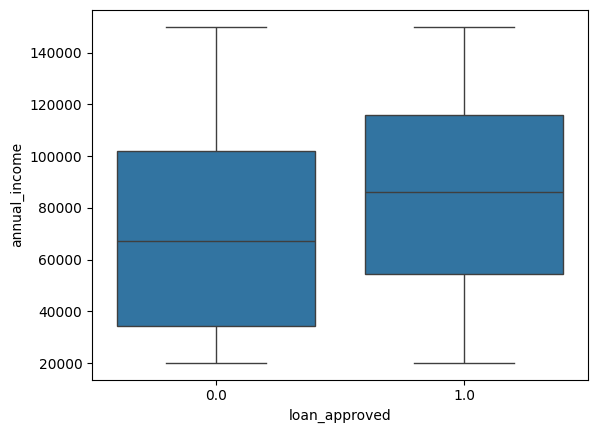

In [23]:
# outluiers- box plots
sns.boxplot(
    data=df,
    x="loan_approved",
    y="annual_income"
)

<Axes: xlabel='loan_approved', ylabel='num_dependents'>

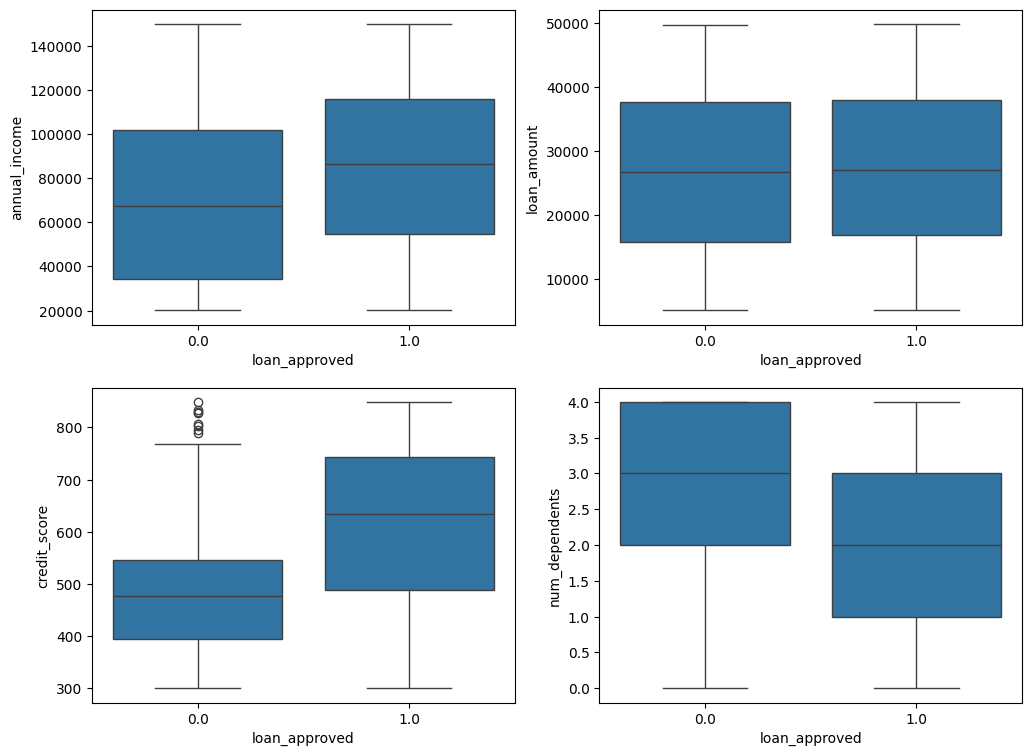

In [24]:
fig,axes=plt.subplots(2,2,figsize=(12, 9))

sns.boxplot(ax=axes[0,0],data=df,x="loan_approved",y="annual_income")
sns.boxplot(ax=axes[0,1],data=df,x="loan_approved",y="loan_amount")
sns.boxplot(ax=axes[1,0],data=df,x="loan_approved",y="credit_score")
sns.boxplot(ax=axes[1,1],data=df,x="loan_approved",y="num_dependents")

<Axes: xlabel='credit_score', ylabel='Count'>

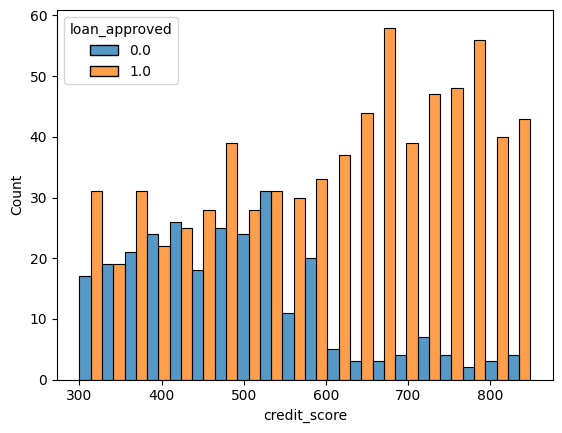

In [25]:
# credit_score with loan _approved
sns.histplot(
    data=df,
    x="credit_score",
    hue="loan_approved",
    bins=20,
    multiple="dodge"
)

In [26]:
# Remove Applicant ID
df=df.drop("applicant_id",axis=1)

In [27]:
df.head()

,age,gender,marital_status,annual_income,loan_amount,credit_score,num_dependents,existing_loans_count,employment_status,loan_approved
0,59.0,Male,Divorced,100073.0,7169.0,793.0,1.0,1.0,Unemployed,1.0
1,49.0,Male,Married,112197.0,23556.0,789.0,0.0,2.0,Employed,1.0
2,35.0,Male,Divorced,84429.0,27052.0,372.0,1.0,4.0,Unemployed,0.0
3,63.0,Female,Single,124195.0,11313.0,808.0,3.0,4.0,Self-employed,1.0
4,28.0,Female,Married,81627.0,13315.0,689.0,0.0,1.0,Unemployed,1.0


# Encoding

In [28]:
df.head()
df.columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   1000 non-null   float64
 1   gender                1000 non-null   object 
 2   marital_status        1000 non-null   object 
 3   annual_income         1000 non-null   float64
 4   loan_amount           1000 non-null   float64
 5   credit_score          1000 non-null   float64
 6   num_dependents        1000 non-null   float64
 7   existing_loans_count  1000 non-null   float64
 8   employment_status     1000 non-null   object 
 9   loan_approved         1000 non-null   float64
dtypes: float64(7), object(3)
memory usage: 78.3+ KB


In [29]:
from sklearn.preprocessing import LabelEncoder,OneHotEncoder

le=LabelEncoder()
df["gender"]=le.fit_transform(df["gender"])
df["marital_status"]=le.fit_transform(df["marital_status"])
df["employment_status"]=le.fit_transform(df["employment_status"])


In [30]:
df.head()

,age,gender,marital_status,annual_income,loan_amount,credit_score,num_dependents,existing_loans_count,employment_status,loan_approved
0,59.0,1,0,100073.0,7169.0,793.0,1.0,1.0,2,1.0
1,49.0,1,1,112197.0,23556.0,789.0,0.0,2.0,0,1.0
2,35.0,1,0,84429.0,27052.0,372.0,1.0,4.0,2,0.0
3,63.0,0,2,124195.0,11313.0,808.0,3.0,4.0,1,1.0
4,28.0,0,1,81627.0,13315.0,689.0,0.0,1.0,2,1.0


In [31]:
cols = ["gender", "marital_status", "employment_status"]

ohe = OneHotEncoder(
    drop="first",
    sparse_output=False,
    handle_unknown="ignore"
)

encoded = ohe.fit_transform(df[cols])

encoded_df = pd.DataFrame(
    encoded,
    columns=ohe.get_feature_names_out(cols)
)

encoded_df.head()

,gender_1,marital_status_1,marital_status_2,employment_status_1,employment_status_2
0,1.0,0.0,0.0,0.0,1.0
1,1.0,1.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,1.0
3,0.0,0.0,1.0,1.0,0.0
4,0.0,1.0,0.0,0.0,1.0


In [32]:
df=pd.concat([df.drop(columns=cols),encoded_df],axis=1)

In [33]:
df.head()

,age,annual_income,loan_amount,credit_score,num_dependents,existing_loans_count,loan_approved,gender_1,marital_status_1,marital_status_2,employment_status_1,employment_status_2
0,59.0,100073.0,7169.0,793.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0
1,49.0,112197.0,23556.0,789.0,0.0,2.0,1.0,1.0,1.0,0.0,0.0,0.0
2,35.0,84429.0,27052.0,372.0,1.0,4.0,0.0,1.0,0.0,0.0,0.0,1.0
3,63.0,124195.0,11313.0,808.0,3.0,4.0,1.0,0.0,0.0,1.0,1.0,0.0
4,28.0,81627.0,13315.0,689.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0


In [34]:
df.shape

(1000, 12)

In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   1000 non-null   float64
 1   annual_income         1000 non-null   float64
 2   loan_amount           1000 non-null   float64
 3   credit_score          1000 non-null   float64
 4   num_dependents        1000 non-null   float64
 5   existing_loans_count  1000 non-null   float64
 6   loan_approved         1000 non-null   float64
 7   gender_1              1000 non-null   float64
 8   marital_status_1      1000 non-null   float64
 9   marital_status_2      1000 non-null   float64
 10  employment_status_1   1000 non-null   float64
 11  employment_status_2   1000 non-null   float64
dtypes: float64(12)
memory usage: 93.9 KB


# Correlation Heatmap

<Axes: >

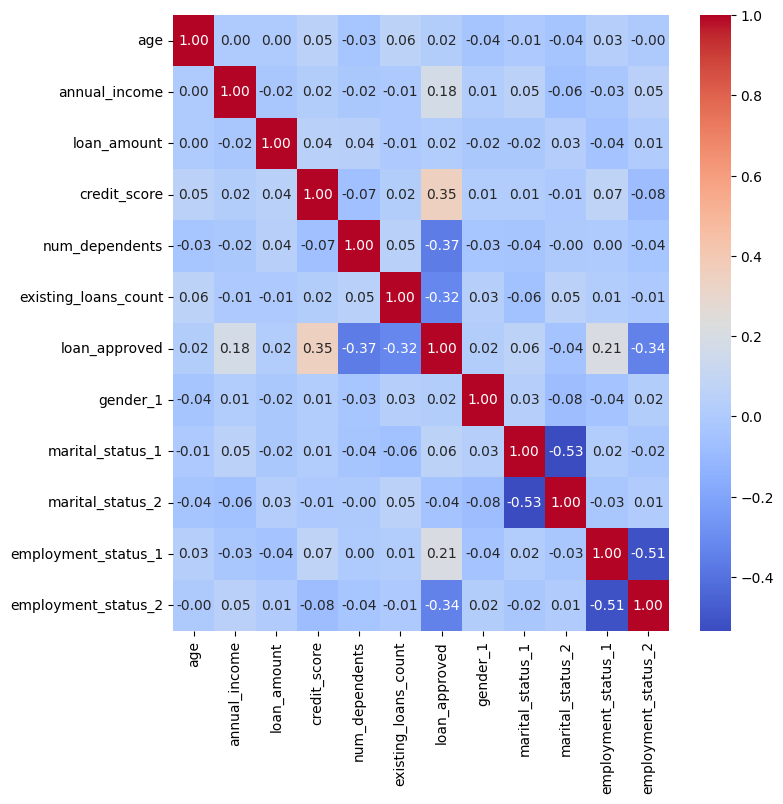

In [36]:
nums_cols=df.select_dtypes(include="number")
corr_matrix=nums_cols.corr()

plt.figure(figsize=(8,8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

# Train -Test-Split + Feature Scaling



In [37]:
x=df.drop("loan_approved",axis=1)
y=df["loan_approved"]

In [38]:
x

,age,annual_income,loan_amount,credit_score,num_dependents,existing_loans_count,gender_1,marital_status_1,marital_status_2,employment_status_1,employment_status_2
0,59.0,100073.0,7169.0,793.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0
1,49.0,112197.0,23556.0,789.0,0.0,2.0,1.0,1.0,0.0,0.0,0.0
2,35.0,84429.0,27052.0,372.0,1.0,4.0,1.0,0.0,0.0,0.0,1.0
3,63.0,124195.0,11313.0,808.0,3.0,4.0,0.0,0.0,1.0,1.0,0.0
4,28.0,81627.0,13315.0,689.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...
995,53.0,135598.0,6014.0,767.0,3.0,2.0,0.0,1.0,0.0,0.0,0.0
996,22.0,139028.0,15103.0,662.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0
997,34.0,147517.0,21986.0,582.0,0.0,2.0,0.0,1.0,0.0,0.0,0.0
998,60.0,73161.0,49781.0,635.0,4.0,0.0,0.0,0.0,0.0,0.0,1.0


In [39]:
y

0      1.0
1      1.0
2      0.0
3      1.0
4      1.0
      ... 
995    1.0
996    1.0
997    1.0
998    1.0
999    1.0
Name: loan_approved, Length: 1000, dtype: float64

In [40]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [41]:
x_train.head()

,age,annual_income,loan_amount,credit_score,num_dependents,existing_loans_count,gender_1,marital_status_1,marital_status_2,employment_status_1,employment_status_2
29,47.0,83646.0,26300.0,428.0,1.0,4.0,1.0,0.0,0.0,0.0,0.0
535,56.0,92954.0,26542.0,301.0,4.0,4.0,0.0,1.0,0.0,0.0,1.0
695,48.0,134604.0,35581.0,329.0,2.0,3.0,1.0,1.0,0.0,0.0,1.0
557,59.0,28472.0,48463.0,397.0,4.0,4.0,1.0,0.0,1.0,0.0,1.0
836,55.0,39086.0,43811.0,329.0,1.0,2.0,1.0,1.0,0.0,1.0,0.0


In [42]:
x_test.head()

,age,annual_income,loan_amount,credit_score,num_dependents,existing_loans_count,gender_1,marital_status_1,marital_status_2,employment_status_1,employment_status_2
521,57.0,68781.0,39064.0,572.0,2.0,4.0,0.0,1.0,0.0,1.0,0.0
737,34.0,26796.0,25238.0,689.0,1.0,2.0,0.0,0.0,1.0,0.0,1.0
740,59.0,63056.0,28749.0,687.0,4.0,3.0,0.0,1.0,0.0,1.0,0.0
660,37.0,79871.0,42044.0,732.0,4.0,1.0,0.0,0.0,1.0,0.0,1.0
411,46.0,148734.0,18767.0,348.0,3.0,0.0,1.0,0.0,1.0,0.0,0.0


In [43]:
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()

x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [44]:
x_train_scaled

array([[ 0.33275925,  0.01372064, -0.07570696, ..., -0.72174272,
        -0.73581643, -0.69982706],
       [ 1.04243537,  0.2645305 , -0.0568871 , ..., -0.72174272,
        -0.73581643,  1.42892445],
       [ 0.41161215,  1.38681569,  0.64605787, ..., -0.72174272,
        -0.73581643,  1.42892445],
       ...,
       [ 0.88472957, -0.08296025,  0.10160409, ..., -0.72174272,
        -0.73581643,  1.42892445],
       [ 0.41161215, -1.68388054,  1.25863643, ..., -0.72174272,
        -0.73581643, -0.69982706],
       [ 1.51555279, -0.74401722, -1.51379285, ..., -0.72174272,
         1.35903462, -0.69982706]])

In [45]:
x_test_scaled

array([[ 1.12128827, -0.38682604,  0.91692382, ..., -0.72174272,
         1.35903462, -0.69982706],
       [-0.69232848, -1.51813802, -0.15829657, ...,  1.38553529,
        -0.73581643,  1.42892445],
       [ 1.27899408, -0.54108973,  0.11474688, ..., -0.72174272,
         1.35903462, -0.69982706],
       ...,
       [-1.3231517 ,  0.21101649,  1.10395587, ..., -0.72174272,
         1.35903462, -0.69982706],
       [-0.77118139,  0.22166002, -0.91396825, ..., -0.72174272,
        -0.73581643, -0.69982706],
       [-0.53462268,  1.62054203, -0.42107465, ..., -0.72174272,
        -0.73581643,  1.42892445]])

# Train & Evaluate Models



In [46]:
# # Logistic Regression

# from sklearn.linear_model import LogisticRegression
# from sklearn.metrics import confusion_matrix,accuracy_score,precision_score,recall_score,f1_score

# log_model=LogisticRegression()
# log_model.fit(x_train_scaled,y_train)
# #
# y_pred=log_model.predict(x_test_scaled)

# # evaluation

# print("LogisticRegression Model")
# print("Precision:", precision_score(y_test,y_pred))
# print("Recall:", recall_score(y_test,y_pred))
# print("F1 Score:", f1_score(y_test,y_pred))
# print("Accuray Score:", accuracy_score(y_test,y_pred))
# print("CM:", confusion_matrix(y_test,y_pred))





In [47]:
# # KNN 

# from sklearn.neighbors import KNeighborsClassifier
# from sklearn.metrics import confusion_matrix,accuracy_score,precision_score,recall_score,f1_score

# knn_model=KNeighborsClassifier(n_neighbors=5)
# knn_model.fit(x_train_scaled,y_train)

# y_pred=knn_model.predict(x_test_scaled)

# # evaluation

# print("KNN Model")
# print("Precision:", precision_score(y_test,y_pred))
# print("Recall:", recall_score(y_test,y_pred))
# print("F1 Score:", f1_score(y_test,y_pred))
# print("Accuray Score:", accuracy_score(y_test,y_pred))
# print("CM:", confusion_matrix(y_test,y_pred))





In [48]:
# # Naive Bayes

# from sklearn.naive_bayes import GaussianNB
# from sklearn.metrics import confusion_matrix,accuracy_score,precision_score,recall_score,f1_score

# NB_model=GaussianNB()
# NB_model.fit(x_train_scaled,y_train)

# y_pred=NB_model.predict(x_test_scaled)

# # evaluation

# print("Naive Bayes Model")
# print("Precision:", precision_score(y_test,y_pred))
# print("Recall:", recall_score(y_test,y_pred))
# print("F1 Score:", f1_score(y_test,y_pred))
# print("Accuray Score:", accuracy_score(y_test,y_pred))
# print("CM:", confusion_matrix(y_test,y_pred))


# # best Model is Naive Bayes





# Feature Engineering 

In [49]:
# ADD or Transform Features
df["num_dependents_sq"]=df["num_dependents"]**2
df["credit_score_sq"]=df["credit_score"]**2

x=df.drop(columns=["loan_approved","credit_score","num_dependents"])
y=df["loan_approved"]

# train test split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

# scaling
scaler=StandardScaler()

x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [50]:
# # Logistic Regression

# from sklearn.linear_model import LogisticRegression
# from sklearn.metrics import confusion_matrix,accuracy_score,precision_score,recall_score,f1_score

# log_model=LogisticRegression()
# log_model.fit(x_train_scaled,y_train)

# y_pred=log_model.predict(x_test_scaled)

# # evaluation

# print("LogisticRegression Model")
# print("Precision:", precision_score(y_test,y_pred))
# print("Recall:", recall_score(y_test,y_pred))
# print("F1 Score:", f1_score(y_test,y_pred))
# print("Accuray Score:", accuracy_score(y_test,y_pred))
# print("CM:", confusion_matrix(y_test,y_pred))





In [51]:
# # KNN 

# from sklearn.neighbors import KNeighborsClassifier
# from sklearn.metrics import confusion_matrix,accuracy_score,precision_score,recall_score,f1_score

# knn_model=KNeighborsClassifier(n_neighbors=5)
# knn_model.fit(x_train_scaled,y_train)

# y_pred=knn_model.predict(x_test_scaled)

# # evaluation

# print("KNN  Model")
# print("Precision:", precision_score(y_test,y_pred))
# print("Recall:", recall_score(y_test,y_pred))
# print("F1 Score:", f1_score(y_test,y_pred))
# print("Accuray Score:", accuracy_score(y_test,y_pred))
# print("CM:", confusion_matrix(y_test,y_pred))





In [ ]:
# Naive Bayes

from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix,accuracy_score,precision_score,recall_score,f1_score


NB_model = GaussianNB()
NB_model.fit(x_train_scaled, y_train)

y_pred=NB_model.predict(x_test_scaled)

# evaluation

print("Naive Bayes Model")
print("Precision:", precision_score(y_test,y_pred))
print("Recall:", recall_score(y_test,y_pred))
print("F1 Score:", f1_score(y_test,y_pred))
print("Accuray Score:", accuracy_score(y_test,y_pred))
print("CM:", confusion_matrix(y_test,y_pred))


# best Model is Naive Bayes





LogisticRegression Model
Precision: 0.8954248366013072
Recall: 0.9448275862068966
F1 Score: 0.9194630872483222
Accuray Score: 0.88
CM: [[ 39  16]
 [  8 137]]


In [58]:
print("Model:", NB_model)
print("Model type:", type(NB_model))

Model: GaussianNB()
Model type: <class 'sklearn.naive_bayes.GaussianNB'>


In [59]:
import joblib

loan_artifact = {
    "model": NB_model,
    "scaler": scaler,
    "feature_names": list(x.columns)
}

joblib.dump(loan_artifact, "loan_approval_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [60]:
artifact = joblib.load("loan_approval_model.pkl")

print("Saved model:", artifact["model"])
print("Saved model type:", type(artifact["model"]))
print("Saved scaler type:", type(artifact["scaler"]))
print("Features:", artifact["feature_names"])

Saved model: GaussianNB()
Saved model type: <class 'sklearn.naive_bayes.GaussianNB'>
Saved scaler type: <class 'sklearn.preprocessing._data.StandardScaler'>
Features: ['age', 'annual_income', 'loan_amount', 'existing_loans_count', 'gender_1', 'marital_status_1', 'marital_status_2', 'employment_status_1', 'employment_status_2', 'num_dependents_sq', 'credit_score_sq']
